In [ ]:
Descriptive Statistics


<font size = "5">

Import Libraries

In [1]:
import pandas as pd

<font size = "5">

Import Data

- Food Policy Bills in the United States

In [3]:
food_policy_actions = pd.read_csv("policy_data_selenium.csv")
food_policy_actions.dtypes

jurisdiction         object
jurisdiction_type    object
state                object
policy_category      object
summary              object
url                  object
dtype: object

In [5]:
food_policy_actions["policy_category"]
#first thing I need to do is set up categories for the text that I am mining

0      Distribute; Get
1                 Grow
2                  NaN
3                  Get
4            Grow; Get
            ...       
600                NaN
601          Grow; Get
602    Distribute; Get
603                NaN
604               Make
Name: policy_category, Length: 605, dtype: object

In [6]:
food_policy_actions["policy_category"].value_counts()
#this is how I get a count of how many I have within each category

policy_category
Distribute; Get                                  120
Grow; Get                                        118
Grow                                              53
Get                                               43
Make                                              17
Grow; Distribute                                  12
Distribute                                        10
Surplus                                            8
Process; Get                                       7
Distribute; Surplus                                6
Process; Distribute                                6
Grow; Surplus                                      5
Grow; Process; Distribute; Get; Make; Surplus      5
Process; Distribute; Get                           3
Get; Surplus                                       3
Grow; Process                                      3
Get; Make                                          2
Grow; Make                                         2
Distribute; Make              

In [7]:
has_get = food_policy_actions["policy_category"].str.contains("Get")
print(has_get.sum())

306


In [8]:
for category in ["Grow", "Process", "Distribute", "Get", "Make", "Surplus"]:
    print(category, food_policy_actions["policy_category"].str.contains(category).sum())

Grow 202
Process 27
Distribute 169
Get 306
Make 31
Surplus 30


Rather than using the action words used to identify the categories, I want to change them to more commonly used terms within food systems. This will alow for future analyses to be more congruent with another policy datasets. 

In [24]:
list_old = ["Grow", "Process", "Distribute", "Get", "Make", "Surplus"]
list_new = ["Food Production", "Food Processing", "Food Distribution", "Food Access",
            "Food Prep and Safety", "Food Recovery and Waste Management"]

# Count policies containing each category (original data untouched)
counts = []
for i in range(len(list_old)):
    n = food_policy_actions["policy_category"].str.contains(list_old[i]).sum()
    counts.append(n)

table_category = pd.DataFrame({"Category": list_new, "Number of Policies": counts})
table_category

,Category,Number of Policies
0,Food Production,202
1,Food Processing,27
2,Food Distribution,169
3,Food Access,306
4,Food Prep and Safety,31
5,Food Recovery and Waste Management,30


In [25]:
table_category = table_category.set_index("Category")
table_category

,Number of Policies
Category,
Food Production,202
Food Processing,27
Food Distribution,169
Food Access,306
Food Prep and Safety,31
Food Recovery and Waste Management,30


In [26]:
table_category["Proportion of Policies"] = table_category["Number of Policies"] / 605
table_category

,Number of Policies,Proportion of Policies
Category,,
Food Production,202,0.333884
Food Processing,27,0.044628
Food Distribution,169,0.279339
Food Access,306,0.505785
Food Prep and Safety,31,0.051240
Food Recovery and Waste Management,30,0.049587


In [27]:
table_category = table_category.drop(columns = "Proportion of Policies")
table_category

,Number of Policies
Category,
Food Production,202
Food Processing,27
Food Distribution,169
Food Access,306
Food Prep and Safety,31
Food Recovery and Waste Management,30


In [23]:
table_category.reset_index().style.hide(axis = "index") \
    .set_properties(subset = ["Category"], **{"text-align": "left", "white-space": "normal", "min-width": "250px"}) \
    .set_properties(subset = ["Number of Policies", "Percent of Policies"], **{"text-align": "center"}) \
    .format({"Percent of Policies": "{:.1f}%"}) \
    .bar(subset = ["Percent of Policies"], color = "#5fa8d3", vmin = 0, vmax = 100) \
    .set_table_styles([{"selector": "th",
                        "props": [("text-align", "center"),
                                  ("font-weight", "bold"),
                                  ("background-color", "white"),
                                  ("border-bottom", "2px solid black")]}])

Category,Number of Policies,Percent of Policies
Food Access,306,50.6%
Food Production,202,33.4%
Distribution,169,27.9%
Food Prep and Safety,31,5.1%
Food Recovery and Waste Management,30,5.0%
Food Processing,27,4.5%


Half of the food policies respond to food access, 33.4% address food production and 27.9% relate to food distribution. Note that most policies cover more than one category.

In [ ]:
CODEBOOK = {
    "maternal_pregnancy": [
        "mother", "mothers", "maternal", "maternity",
        "pregnant", "pregnancy", "prenatal", "perinatal", "postpartum",
        "birth", "doula", "midwife", "obstetric",
        "parental leave", "family leave",
    ],
    "breastfeeding_lactation": [
        "breast milk", "breastfeed", "breastfeeding", "breast-feed",
        "lactation", "nursing mother",
    ],
    "infant_early_childhood": [
        "infant", "infants", "newborn", "baby", "babies", "toddler",
        "infant formula", "early childhood", "early learning",
        "pre-k", "pre-kindergarten", "preschool",
        "head start", "early head start",
    ],
    "child_care": [
        "child care", "childcare", "day care", "daycare",
        "child care learning center", "family child care learning home",
        "after-school", "afterschool", "after school",
    ],
    "children_youth": [
        "child", "children", "childhood", "kid", "kids",
        "youth", "minor", "minors", "adolescent",
        "teen", "teens", "teenager", "juvenile",
        "under 18", "under the age of",
    ],
    "schools_education": [
        "school", "schools", "student", "students", "k-12",
        "school district", "board of education",
        "school zone", "safe routes to school",
    ],
    "child_nutrition_programs": [
        "school lunch", "school breakfast", "school meal",
        "summer meal", "nslp", "sbp", "cacfp", "sfsp",
        "seamless summer", "summer ebt", "sun bucks",
        "free and reduced", "community eligibility",
        "farm to school", "smart snacks", "competitive food",
    ],
    "food_benefits": [
        "snap", "wic", "ebt", "tanf",
        "supplemental nutrition assistance",
        "women, infants, and children",
    ],
    "health_coverage": [
        "medicaid", "peachcare",
    ],
    "family_household": [
        "family", "families", "parent", "parents", "parenting",
        "guardian", "caregiver", "dependent",
        "household with children", "foster care", "custody",
        "child tax credit",
    ],
    "georgia_agencies": [
        "decal", "caps", "quality rated", "georgia pre-k",
        "dfcs", "gadoe", "department of public health",
    ],
    "play_recreation": [
        "playground", "play area", "recreation center",
        "tot lot", "splash pad",
    ],
    "food_environment_marketing": [
        "candy", "sugar-sweetened beverage", "sugary drink",
        "vending", "marketing to children", "lead",
    ],
}

In [29]:
text_col = "summary"   # change to your text column name

for category in CODEBOOK:
    found = False
    for term in CODEBOOK[category]:
        found = found | food_policy_actions[text_col].str.contains(term, case = False, regex = False, na = False)
    food_policy_actions[category] = found

for category in CODEBOOK:
    print(category, food_policy_actions[category].sum())

maternal_pregnancy 10
breastfeeding_lactation 12
infant_early_childhood 11
child_care 7
children_youth 66
schools_education 40
child_nutrition_programs 4
food_benefits 18
health_coverage 1
family_household 23
georgia_agencies 3
play_recreation 3
food_environment_marketing 25


In [30]:
counts = []
for category in CODEBOOK:
    counts.append(food_policy_actions[category].sum())

table_codebook = pd.DataFrame({"Category": list(CODEBOOK.keys()), "Number of Policies": counts})
table_codebook["Percent of Policies"] = (table_codebook["Number of Policies"] / 605 * 100).round(1)
table_codebook = table_codebook.sort_values("Number of Policies", ascending = False)

table_codebook.style.hide(axis = "index") \
    .set_properties(subset = ["Category"], **{"text-align": "left", "white-space": "normal", "min-width": "250px"}) \
    .set_properties(subset = ["Number of Policies", "Percent of Policies"], **{"text-align": "center"}) \
    .format({"Percent of Policies": "{:.1f}%"}) \
    .bar(subset = ["Percent of Policies"], color = "#5fa8d3", vmin = 0, vmax = 100) \
    .set_table_styles([{"selector": "th",
                        "props": [("text-align", "center"),
                                  ("font-weight", "bold"),
                                  ("background-color", "white"),
                                  ("border-bottom", "2px solid black")]}])

Category,Number of Policies,Percent of Policies
children_youth,66,10.9%
schools_education,40,6.6%
food_environment_marketing,25,4.1%
family_household,23,3.8%
food_benefits,18,3.0%
breastfeeding_lactation,12,2.0%
infant_early_childhood,11,1.8%
maternal_pregnancy,10,1.7%
child_care,7,1.2%
child_nutrition_programs,4,0.7%


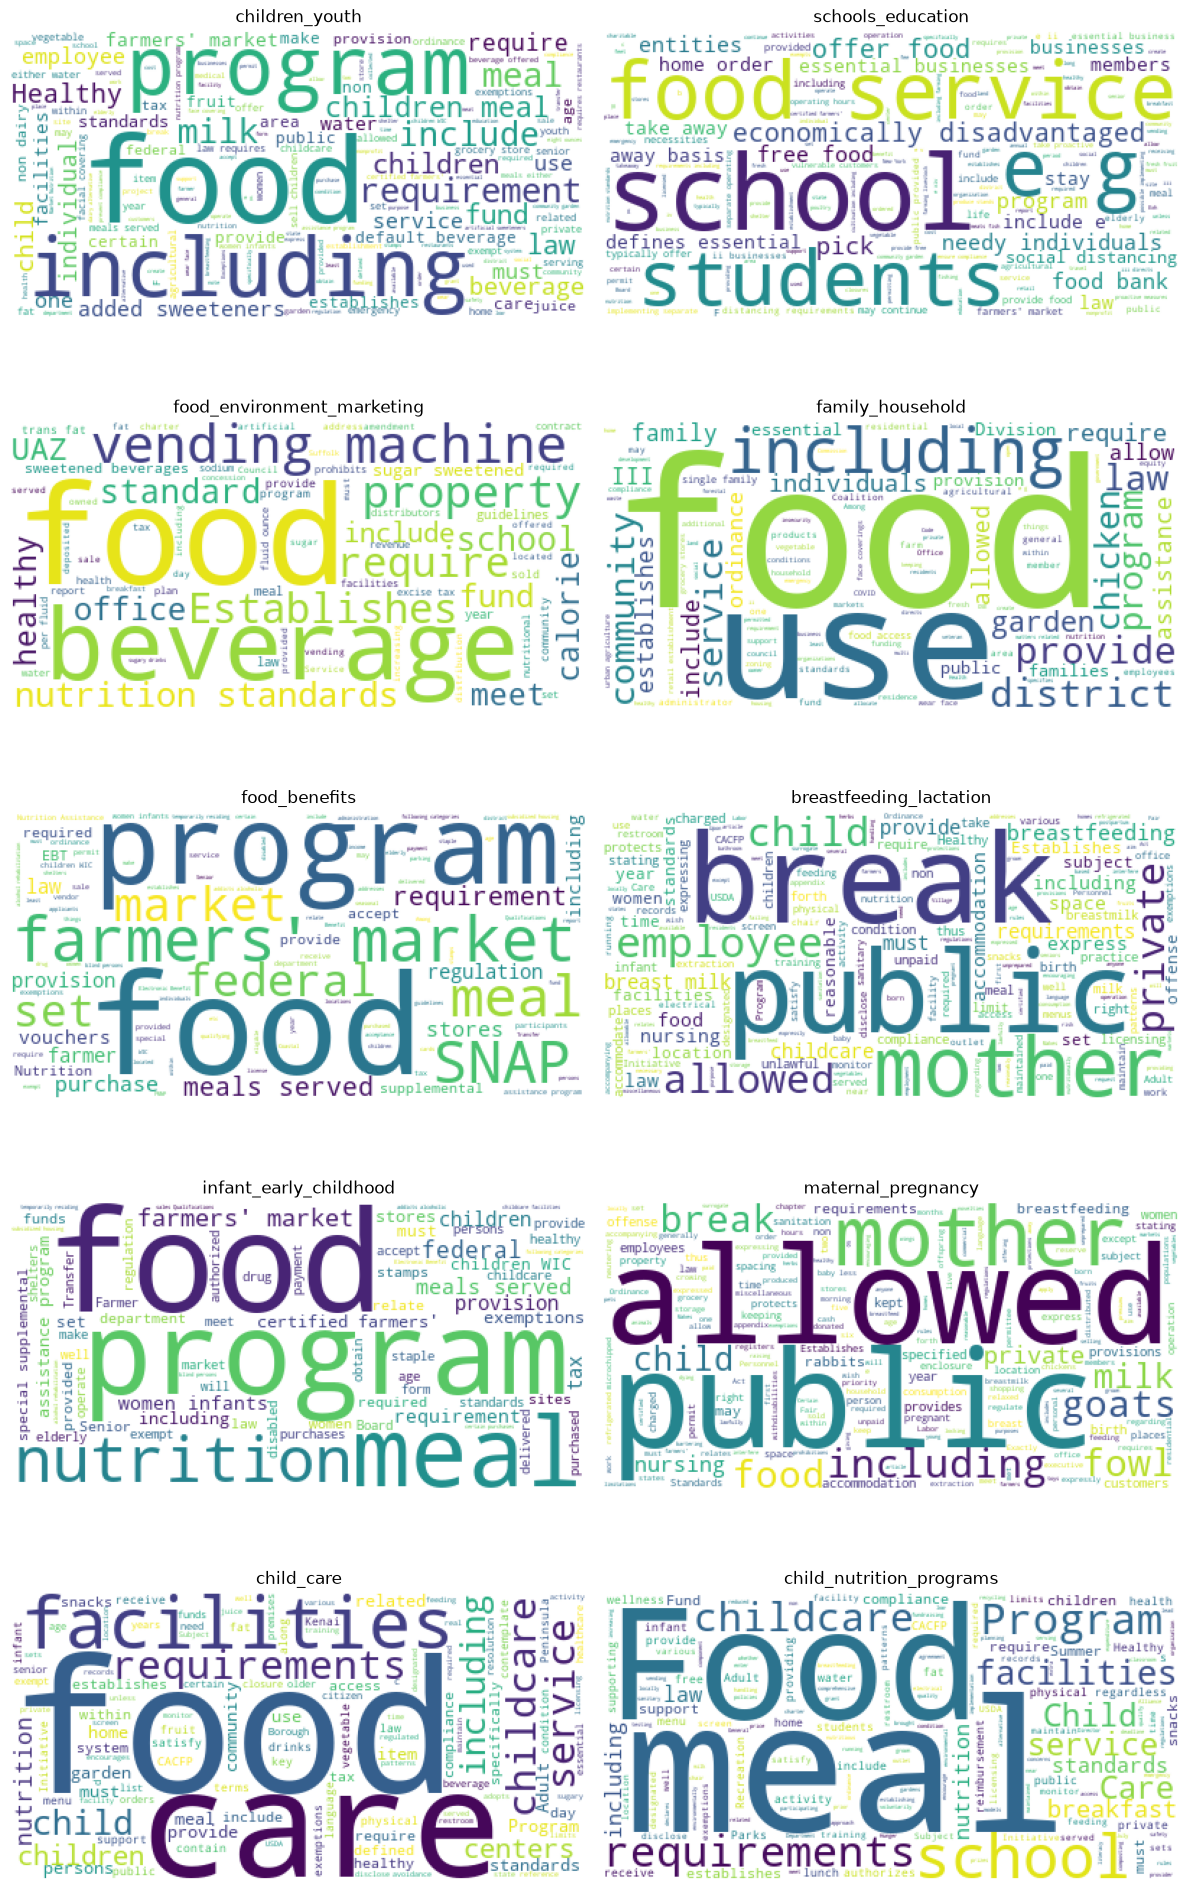

In [38]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

text_col = "summary"   # change to your text column name

# Top ten categories by number of policies
list_top10 = list(table_codebook["Category"].head(10))

# Add words that appear everywhere and carry no meaning for your question
stop_words = list(STOPWORDS) + ["policy", "section", "city", "county"]

fig, axes = plt.subplots(5, 2, figsize = (12, 20))
axes = axes.flatten()

for i in range(len(list_top10)):
    category = list_top10[i]
    subset = food_policy_actions[food_policy_actions[category]]
    text = " ".join(subset[text_col].dropna())

    word_cloud = WordCloud(background_color = "white",
                           stopwords = stop_words).generate(text)

    axes[i].imshow(word_cloud)
    axes[i].set_title(category)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [35]:
type_col = "jurisdiction_type"   # change to your column name
print(food_policy_actions[type_col].value_counts())

jurisdiction_type
City                              404
County                            123
City, County                       27
Town/Township                      25
Other.                             16
Other. Metropolitan Government      4
Other. Borough                      2
Other. Parish                       1
Other. Municipality                 1
Other. Island                       1
Name: count, dtype: int64


In [37]:
type_col = "jurisdiction_type"

list_types = ["City", "County", "Town/Township", "Other."]
list_labels = ["City", "County", "Town/Township", "Other (borough, parish, metro government, etc.)"]

counts = []
for t in list_types:
    counts.append(food_policy_actions[type_col].str.contains(t, regex = False, na = False).sum())

table_type = pd.DataFrame({"Jurisdiction Type": list_labels, "Number of Policies": counts})
table_type["Percent of Policies"] = (table_type["Number of Policies"] / len(food_policy_actions) * 100).round(1)
table_type = table_type.sort_values("Number of Policies", ascending = False)

table_type.style.hide(axis = "index") \
    .set_properties(subset = ["Jurisdiction Type"], **{"text-align": "left", "white-space": "normal", "min-width": "250px"}) \
    .set_properties(subset = ["Number of Policies", "Percent of Policies"], **{"text-align": "center"}) \
    .format({"Percent of Policies": "{:.1f}%"}) \
    .bar(subset = ["Percent of Policies"], color = "#5fa8d3", vmin = 0, vmax = 100) \
    .set_table_styles([{"selector": "th",
                        "props": [("text-align", "center"),
                                  ("font-weight", "bold"),
                                  ("background-color", "white"),
                                  ("border-bottom", "2px solid black")]}])

Jurisdiction Type,Number of Policies,Percent of Policies
City,431,71.2%
County,150,24.8%
Town/Township,25,4.1%
"Other (borough, parish, metro government, etc.)",25,4.1%


In [39]:
list_cats = ["breastfeeding_lactation", "child_care", "child_nutrition_programs"]

# Policies matching at least one of the three categories
subset = food_policy_actions[food_policy_actions[list_cats].any(axis = 1)].copy()

# Readable list of which of the three categories each policy matched
list_matched = []
for i in range(len(subset)):
    matched = []
    for cat in list_cats:
        if subset.iloc[i][cat]:
            matched.append(cat)
    list_matched.append(", ".join(matched))
subset["Codebook Categories"] = list_matched

table_policies = subset[["jurisdiction", "state", "jurisdiction_type", "policy_category", "Codebook Categories", "summary"]]
table_policies.columns = ["Jurisdiction", "State", "Jurisdiction Type", "Policy Category", "Codebook Categories", "Summary"]
table_policies = table_policies.sort_values(["Codebook Categories", "State", "Jurisdiction"]).reset_index(drop = True)

print(len(table_policies))

table_policies.style.hide(axis = "index") \
    .set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top"}) \
    .set_properties(subset = ["Summary"], **{"min-width": "400px"}) \
    .set_properties(subset = ["Jurisdiction", "Policy Category", "Codebook Categories"], **{"min-width": "150px"}) \
    .set_table_styles([{"selector": "th",
                        "props": [("text-align", "center"),
                                  ("font-weight", "bold"),
                                  ("background-color", "white"),
                                  ("border-bottom", "2px solid black")]}])


20


Jurisdiction,State,Jurisdiction Type,Policy Category,Codebook Categories,Summary
Chandler,Arizona,City,Get,breastfeeding_lactation,"This law protects women who are breastfeeding in public and private places, stating that they they are allowed to so in any location (public or private) that mother and child are otherwise allowed to be (and thus not subject to being charged with a miscellaneous offense)."
Tempe,Arizona,City,Get,breastfeeding_lactation,"This law protects women who are breastfeeding in public places, stating that they they are allowed to so in any public spaces that mother and child are otherwise allowed to be (and thus not subject to being charged with a general offense)."
Alachua,Florida,City,Get,breastfeeding_lactation,"Establishes that city employees must be allowed unpaid work breaks for expressing breast milk for up to one year after the child's birth, with other accommodations, including use of private office space for milk extraction."
Godfrey,Illinois,Other.,Get,breastfeeding_lactation,"Upon the employee's request, the Village must provide a ""reasonable accommodation"" of providing private, non-bathroom space to its employees for the purpose of expressing breast milk and breastfeeding."
Passaic,New Jersey,City,Distribute; Get,breastfeeding_lactation,"This article provides rules, regulations and standards for operation of farmers' markets with the aim of ""encouraging the consumption of locally grown and unprepared fruits, vegetables, and herbs by certified farmers and healthy foods to nutritionally at-risk residents, including pregnant, breastfeeding, or postpartum women, children, and seniors."" It addresses licensing, food handling, sanitation and allowable foods."
Buncombe County,North Carolina,County,Get,breastfeeding_lactation,"This section of the City's Personnel Ordinance and the accompanying appendix set forth the city policy regarding break time for nursing mothers who wish to express breastmilk during the first year after a baby is born. It also provides for refrigerated storage of expressed milk. The language expressly states that ""these provisions will meet the requirements of the Fair Labor Standards Act as it relates to breaks for nursing mothers."""
Philadelphia,Pennsylvania,City,Get,breastfeeding_lactation,Establishes that failing to reasonably accommodate an employee's need to express breastmilk (no limit based on child's age) is an unlawful employment practice. Also sets forth requirements for breaks and conditions of the space necessary to accommodate breast milk expression.
Philadelphia,Pennsylvania,City,Get,breastfeeding_lactation,Establishes that segregating a breastfeeding mother or prohibiting her from being in any public accommodation she otherwise authorized to be is an unlawful public accommodations practice.
Seattle,Washington,City,Get,breastfeeding_lactation,"Allows city employees who qualify under federal law for unpaid breaks to express breast milk to take these breaks without having to take leave or a pay deduction, so long as the breaks are of reasonable length and frequency."
Madison,Wisconsin,City,Get,breastfeeding_lactation,"Makes it an offense against public policy for anyone to interfere with a mother's right (or her surrogate's right) to breastfeed in any location where she is lawfully allowed to be, except private homes."
